# 📱 Impacto das Redes Sociais na Saúde e no Desempenho de Estudantes
### Painel Estatístico em Big Data — Relatório de Análise, Parte 2
*Big Data e Processamento Otimizado com Python II*

| | |
|---|---|
| **Autora** | Indiara, Dialuan e Guilherme
| **Base de dados** | `estudantes.parquet` — 500.000 estudantes, 48 variáveis |
| **Ferramentas** | Python, Polars, Matplotlib e Seaborn |
| **Continuação de** | Parte 1 — filtros, categorização e cruzamento redes × sono × bem-estar |
| **Esta parte** | Distribuição do uso de redes sociais, *outliers* e correlações |

---

## 🧭 Sumário

1. [Resumo executivo](#1-resumo-executivo)
2. [Introdução e conexão com a Parte 1](#2-introdução-e-conexão-com-a-parte-1)
3. [Dados e metodologia](#3-dados-e-metodologia)
4. [Distribuição do uso de redes sociais](#4-distribuição-do-uso-de-redes-sociais)
   - 4.1 [Tendência central e dispersão](#41-tendência-central-e-dispersão)
   - 4.2 [Forma e posição](#42-forma-e-posição)
   - 4.3 [Outliers](#43-outliers)
   - 4.4 [Visualização da distribuição](#44-visualização-da-distribuição)
   - 4.5 [As faixas da Parte 1 sobre a distribuição](#45-as-faixas-da-parte-1-sobre-a-distribuição)
5. [Do resumo ao padrão: bem-estar por faixa de uso e sono](#5-do-resumo-ao-padrão-bem-estar-por-faixa-de-uso-e-sono)
6. [Correlações entre as variáveis do estudo](#6-correlações-entre-as-variáveis-do-estudo)
7. [Exemplo didático: correlação por país](#7-exemplo-didático-correlação-por-país)
8. [Conclusões e limitações](#8-conclusões-e-limitações)
9. [Próximos passos](#9-próximos-passos)

---

## 1. Resumo executivo

| Indicador | Resultado |
|---|---|
| ⏱️ Uso médio de redes sociais | **3,36 h/dia** (mediana de 3,29 h; desvio padrão de 1,29 h) |
| 📊 Metade dos estudantes | entre **2,46 h e 4,20 h** por dia |
| 🔔 Formato da distribuição | **simétrico**, próximo de um sino (assimetria de 0,29 e curtose de 0,05) |
| 🚩 Uso atípico (*outliers*) | **3.563 estudantes** (0,7%), todos acima de **6,81 h** |
| 🔗 Ligação com a Parte 1 | o estudante médio está na faixa *Moderado*; os *outliers* fazem parte da faixa *Alto* (≥ 5 h), que concentra os piores índices de bem-estar |
| 🌍 Correlação por país | fraca e não significativa, e com limitações de desenho da amostra (seção 7) |

> 💡 **Mensagem central:** a Parte 1 mostrou que mais redes e menos sono andam junto com menor bem-estar. A Parte 2 mostra **quem são esses estudantes na distribuição** (uma minoria acima do padrão) e prepara as **correlações no nível do estudante**.

---

## 2. Introdução e conexão com a Parte 1

Na **Parte 1**, os estudantes foram divididos em faixas de uso de redes e de sono, e o cruzamento entre elas revelou o principal resultado do estudo:

| Resultado da Parte 1 | Valor |
|---|---|
| Estudantes com uso > 5 h e sono ≤ 6 h | **10,5%** (52.675) |
| Bem-estar médio: pouco uso e sono bom | **74,11** |
| Bem-estar médio: alto uso e sono baixo | **45,15** (cerca de 29 pontos a menos) |
| Estudantes com sono ≤ 6 h | **49,4%** da amostra |

Esta **Parte 2** responde às perguntas que ficaram em aberto:

1. **Como é a distribuição das horas em redes sociais?** Os cortes de 2 h e 5 h, definidos na Parte 1, ficam em que ponto da distribuição?
2. **Quão atípico é o uso intenso?** Quantos estudantes estão realmente fora do padrão?
3. **Como as variáveis do estudo se relacionam** (redes, sono, bem-estar, atenção, vício digital e risco acadêmico)?

---

## 3. Dados e metodologia

**Fonte:** `estudantes.parquet` (500.000 registros e 48 colunas), lido com `scan_parquet` (execução *lazy*) e coletado apenas quando necessário.

**Variáveis utilizadas:**

| Variável | Uso na análise |
|---|---|
| `horas_redes_sociais` | Variável principal (distribuição, *outliers* e correlações) |
| `horas_sono` | Faixas de sono e correlações |
| `indice_bem_estar` | Indicador de saúde |
| `capacidade_atencao_minutos` | Indicador de atenção |
| `pontuacao_vicio_digital` | Indicador de dependência digital |
| `pontuacao_risco_academico` | Indicador de desempenho acadêmico |
| `pais` | Agrupamento do exemplo didático |

**Técnicas aplicadas:**

| Técnica | Finalidade |
|---|---|
| Média, mediana e moda | Tendência central |
| Variância, desvio padrão e amplitude | Dispersão |
| Quartis, assimetria e curtose | Posição e forma da distribuição |
| Critério do IQR (1,5 × IQR) | Detecção de *outliers* |
| Correlação de Pearson e de Spearman | Associação entre variáveis numéricas |

### 3.1 Bibliotecas

In [3]:
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import pyarrow as pa

### 3.2 Padrão visual do relatório
Define um estilo único para todas as figuras. As cores das faixas (verde, amarelo e vermelho) serão usadas de forma consistente nas seções seguintes.

In [4]:
# Padrão visual do relatório
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})

# Cores das faixas de uso (as mesmas da Parte 1: Baixo, Moderado e Alto)
COR_BAIXO, COR_MODERADO, COR_ALTO = "#4C9F70", "#F2C14E", "#D1495B"

### 3.3 Carga da base

In [5]:
inicial = (
    pl.scan_parquet("estudantes.parquet"))

display(inicial.collect())

id_estudante,pais,nivel_desenvolvimento,taxa_pobreza_percentual,indice_infraestrutura_internet,velocidade_media_internet_mbps,idade,genero,area_urbana_rural,nivel_renda_familiar,acesso_dispositivo,horas_acesso_internet,nivel_escolaridade,area_estudo,motivacao_academica,horas_aprendizado_online,horas_redes_sociais,sessoes_por_dia,duracao_media_sessao_minutos,uso_madrugada,horas_conteudo_educacional,horas_videos_curtos,horas_conteudo_entretenimento,horas_conteudo_noticias,curtidas_por_dia,comentarios_por_dia,posts_por_semana,pontuacao_madrugada,indice_brain_rot,nivel_brain_rot,capacidade_atencao_minutos,horas_estudo_semana,taxa_frequencia_aulas,pontuacao_produtividade,horas_sono,nivel_estresse,pontuacao_ansiedade,pontuacao_depressao,anuncios_vistos_por_dia,anuncios_clicados_por_semana,pontuacao_compra_impulsiva,gasto_digital_mensal,exposicao_cyberbullying,exposicao_conteudo_adulto,pontuacao_vicio_digital,indice_bem_estar,pontuacao_risco_academico,pontuacao_risco_financeiro
i64,str,str,f64,f64,f64,i64,str,str,str,str,f64,str,str,f64,f64,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,i64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,f64,f64,f64,f64
1,"""Catar""","""Em desenvolvimento""",16.3,54.93,27.19,21,"""Masculino""","""Rural""","""Alta""","""Smartphone""",5.24,"""Graduação""","""Negócios""",7.18,10.42,1.1,4.65,16.06,"""Às vezes""",0.24,0.46,0.4,0.33,30.1,4.97,2.11,1,5.87,"""Baixo""",57.55,31.43,95.48,10.0,7.14,4.26,3.19,1.41,38.7,3.12,3.68,79.51,"""Não""","""Não""",8.18,66.66,0.0,26.52
2,"""Estados Unidos""","""Desenvolvido""",8.75,94.39,85.34,25,"""Masculino""","""Urbano""","""Média""","""Smartphone""",6.26,"""Técnico""","""Artes""",5.49,8.15,5.61,15.14,63.08,"""Frequentemente""",0.38,3.31,1.92,0.64,114.39,3.17,5.48,2,29.59,"""Baixo""",51.31,25.98,86.62,7.18,4.0,8.21,8.06,7.7,157.4,18.36,6.54,73.45,"""Não""","""Sim""",22.07,43.89,0.0,39.26
3,"""México""","""Em desenvolvimento""",23.64,47.24,73.55,18,"""Feminino""","""Urbano""","""Baixa""","""Smartphone""",3.44,"""Evasão""",null,5.4,5.15,2.2,7.08,25.78,"""Às vezes""",0.4,0.88,0.92,0.41,56.33,8.24,1.12,1,20.24,"""Baixo""",55.84,21.45,89.63,9.57,6.81,2.93,1.72,1.0,79.6,11.76,5.15,35.75,"""Não""","""Não""",12.59,65.48,0.0,47.54
4,"""Canadá""","""Desenvolvido""",14.51,90.5,188.19,25,"""Masculino""","""Urbano""","""Média""","""Notebook""",4.2,"""Doutorado""","""Ciências Sociais""",7.62,8.67,2.25,8.34,28.28,"""Nunca""",0.86,1.2,0.19,0.81,41.74,7.69,1.82,0,7.36,"""Baixo""",58.03,31.18,93.39,10.0,7.54,4.36,4.86,1.76,69.32,7.91,3.2,47.61,"""Não""","""Sim""",8.01,57.91,0.0,23.44
5,"""Sri Lanka""","""Subdesenvolvido""",62.28,36.84,11.02,15,"""Outro""","""Rural""","""Média""","""Smartphone""",5.42,"""Ensino básico""",null,5.47,8.4,5.38,15.49,58.39,"""Às vezes""",1.06,1.88,2.43,0.57,73.52,16.13,9.81,1,22.35,"""Baixo""",60.0,23.29,92.62,9.34,5.52,6.58,6.03,3.68,144.02,19.43,7.18,82.94,"""Não""","""Não""",21.55,53.69,0.0,47.31
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
499996,"""Canadá""","""Desenvolvido""",14.51,90.5,188.19,21,"""Masculino""","""Urbano""","""Média""","""Ambos""",9.82,"""Graduação""","""Direito""",6.93,10.45,5.9,16.55,68.62,"""Frequentemente""",1.44,2.37,2.09,0.79,88.07,18.72,7.04,2,38.09,"""Moderado""",54.01,24.11,80.82,7.92,4.86,5.18,5.47,6.34,166.46,23.38,8.59,101.37,"""Não""","""Não""",26.53,52.82,0.0,66.51
499997,"""Países Baixos""","""Desenvolvido""",14.7,80.43,107.41,19,"""Masculino""","""Rural""","""Média""","""Smartphone""",4.47,"""Ensino básico""",null,4.98,5.16,3.27,10.55,34.95,"""Frequentemente""",0.48,1.74,1.06,0.37,74.16,2.17,2.77,2,27.74,"""Baixo""",46.43,23.43,87.64,9.11,5.96,5.04,5.07,4.79,96.68,10.49,5.61,62.65,"""Não""","""Não""",17.95,57.49,0.0,42.45
499998,"""Singapura""","""Desenvolvido""",7.12,82.14,217.38,17,"""Feminino""","""Urbano""","""Média""","""Smartphone""",4.78,"""Ensino básico""",null,4.65,5.66,3.1,12.16,31.89,"""Nunca""",0.32,1.7,1.08,0.4,99.03,12.27,3.36,0,22.01,"""Baixo"

> 🔎 **Interpretação.** A base tem 500.000 linhas e 48 colunas, a mesma da Parte 1, e é a fonte de todas as análises seguintes.

---
## 4. Distribuição do uso de redes sociais

### 4.1 Tendência central e dispersão
Medidas: média, mediana, moda, variância, desvio padrão e amplitude total.

In [6]:
# Construindo a expressão de cálculo
metricas1 = inicial.select([
    pl.col("horas_redes_sociais").mean().alias("Média"),
    pl.col("horas_redes_sociais").median().alias("Mediana"),
    # Moda retorna uma lista, pegamos o primeiro valor
    pl.col("horas_redes_sociais").mode().first().alias("Moda"),
    pl.col("horas_redes_sociais").var().alias("Variância"),
    pl.col("horas_redes_sociais").std().alias("Desvio_Padrão"),
    (pl.col("horas_redes_sociais").max() - pl.col("horas_redes_sociais").min()).alias("Amplitude_Total")
]).collect()

print("\n--- Estatísticas Descritivas (Horas em Redes Sociais) ---")
display(metricas1)


--- Estatísticas Descritivas (Horas em Redes Sociais) ---


Média,Mediana,Moda,Variância,Desvio_Padrão,Amplitude_Total
f64,f64,f64,f64,f64,f64
3.360789,3.29,2.88,1.671575,1.292894,9.0


| Medida | Valor |
|---|---|
| Média | 3,36 h |
| Mediana | 3,29 h |
| Moda | 2,88 h |
| Variância | 1,67 |
| Desvio padrão | 1,29 h |
| Amplitude total | 9,0 h |

> 🔎 **Interpretação.**
> - Média (3,36), mediana (3,29) e moda (2,88) são próximas, o que indica uma distribuição equilibrada. A média ligeiramente acima da mediana aponta uma pequena cauda à direita.
> - O desvio padrão de 1,29 h mostra que, em geral, o uso varia cerca de 1,3 h para mais ou para menos em torno da média.
> - A amplitude de 9 h indica que há estudantes com uso próximo de zero e outros com até 9 h por dia.

### 4.2 Forma e posição
Medidas: quartis (Q1, Q2 e Q3), assimetria e curtose.

In [7]:
metricas2 = inicial.select([
    pl.col("horas_redes_sociais").quantile(0.25).alias("Q1"),
    pl.col("horas_redes_sociais").quantile(0.50).alias("Q2"),
    pl.col("horas_redes_sociais").quantile(0.75).alias("Q3"),
    pl.col("horas_redes_sociais").skew().alias("Assimetria"),
    pl.col("horas_redes_sociais").kurtosis().alias("Curtose")
]).collect()

print("\n--- Quartis e Forma da Distribuição ---")
display(metricas2)

# Análise rápida da Assimetria
assimetria = metricas2["Assimetria"][0]
print(f"\nInterpretação da Assimetria ({assimetria:.2f}):")
if -0.5 <= assimetria <= 0.5:
    print("-> Distribuição Simétrica (Dados bem balanceados)")
elif assimetria > 0.5:
    print("-> Assimétrica Positiva (Cauda para a direita - Existem valores muito altos puxando a média)")
else:
    print("-> Assimétrica Negativa (Cauda para a esquerda)")


--- Quartis e Forma da Distribuição ---


Q1,Q2,Q3,Assimetria,Curtose
f64,f64,f64,f64,f64
2.46,3.29,4.2,0.292591,0.047795



Interpretação da Assimetria (0.29):
-> Distribuição Simétrica (Dados bem balanceados)


> 🔎 **Interpretação.**
> - **Quartis:** 25% dos estudantes usam redes por até 2,46 h, 50% por até 3,29 h e 75% por até 4,20 h. O intervalo interquartil (IQR) é de 1,74 h.
> - **Assimetria (0,29):** dentro da faixa considerada simétrica (de -0,5 a 0,5), com leve inclinação para a direita.
> - **Curtose (0,05):** valor próximo de zero, ou seja, caudas semelhantes às de uma distribuição normal, sem excesso de valores extremos.

### 4.3 Outliers
**Critério:** valores abaixo de `Q1 − 1,5 × IQR` ou acima de `Q3 + 1,5 × IQR`.

In [8]:
# 1. Recuperar os valores de Q1 e Q3 calculados acima
Q1 = metricas2["Q1"][0]
Q3 = metricas2["Q3"][0]
IQR = Q3 - Q1

# 2. Definir limites
limite_inferior = Q1 - (1.5 * IQR)
limite_superior = Q3 + (1.5 * IQR)

print(f"\nLimites para Outliers: Inferior ({limite_inferior}) | Superior ({limite_superior})")

# 3. Filtrar e contar os Outliers usando Polars
outliers = inicial.filter(
    (pl.col("horas_redes_sociais") < limite_inferior) |
    (pl.col("horas_redes_sociais") > limite_superior)
).select(["pais", "id_estudante", "horas_redes_sociais"]).collect()

print(f"Quantidade de horas considerados Outliers: {outliers.height}")
print("Exemplos de valores discrepantes:")
display(outliers.head())


Limites para Outliers: Inferior (-0.15000000000000036) | Superior (6.8100000000000005)
Quantidade de horas considerados Outliers: 3563
Exemplos de valores discrepantes:


pais,id_estudante,horas_redes_sociais
str,i64,f64
"""Reino Unido""",71,7.02
"""Alemanha""",343,6.96
"""Emirados Árabes Unidos""",501,6.83
"""Filipinas""",669,6.89
"""Noruega""",1026,6.83


> 🔎 **Interpretação.**
> - Os limites calculados são **-0,15 h** (inferior) e **6,81 h** (superior).
> - Como o limite inferior é negativo e o menor valor possível é zero, **não há *outliers* inferiores**.
> - Foram encontrados **3.563 valores acima de 6,81 h**, cerca de **0,7%** da amostra.
> - Esses valores estão dentro do intervalo possível (até 9 h) e não parecem erros de medição, por isso foram mantidos.

### 4.4 Visualização da distribuição
Histograma com curva de densidade (esquerda) e *boxplot* (direita).

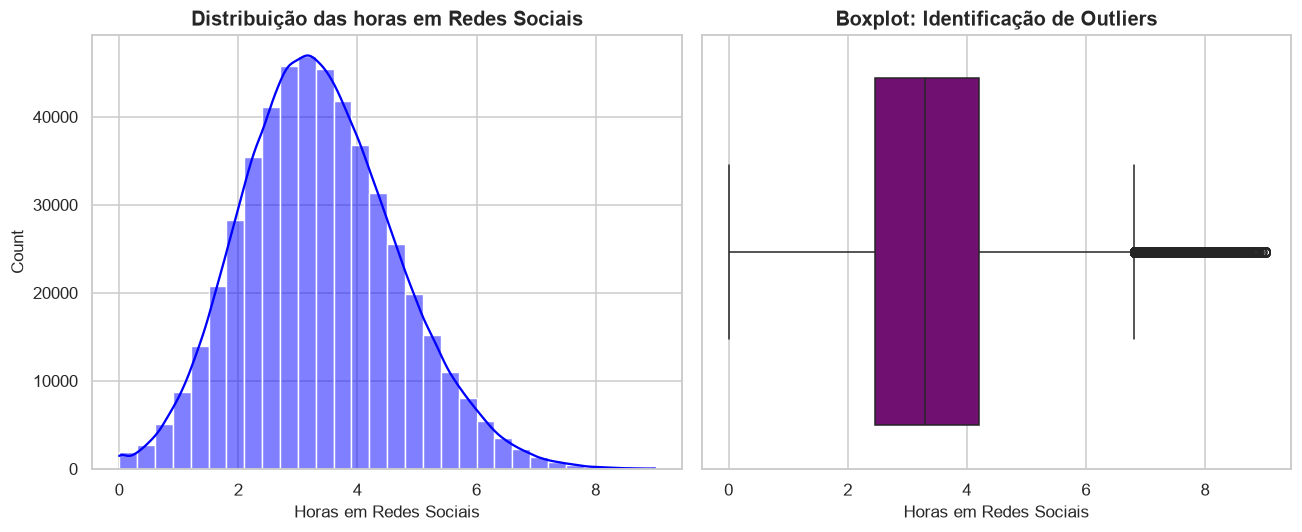

In [9]:
# Coletando a coluna para plotagem
visual = inicial.select("horas_redes_sociais").collect().to_series()

plt.figure(figsize=(12, 5))

# Histograma
plt.subplot(1, 2, 1)
sns.histplot(visual, bins=30, kde=True, color='blue')
plt.title('Distribuição das horas em Redes Sociais')
plt.xlabel('Horas em Redes Sociais')

# Boxplot
plt.subplot(1, 2, 2)
sns.boxplot(x=visual, color='purple')
plt.title('Boxplot: Identificação de Outliers')
plt.xlabel('Horas em Redes Sociais')

plt.tight_layout()
plt.show()

> 🔎 **Interpretação.**
> - O **histograma** tem formato de sino, concentrado entre 2 h e 4,5 h, com pico próximo de 3 h. Isso confirma a simetria indicada pelas medidas.
> - O **boxplot** mostra a mediana ao centro da caixa e todos os *outliers* à direita, a partir de cerca de 6,8 h.

**Recorte da cauda superior:** estudantes com mais de 7 h por dia.

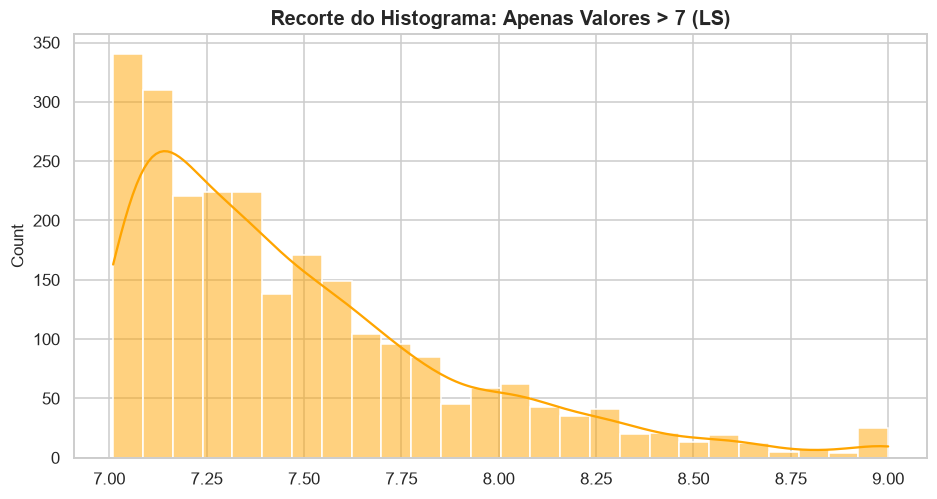

In [10]:

visual_superiores = inicial.filter(pl.col("horas_redes_sociais") > 7).select("horas_redes_sociais").collect().to_series()

plt.figure(figsize=(10, 5))
sns.histplot(visual_superiores, kde=True, color='orange')
plt.title('Recorte do Histograma: Apenas Valores > 7 (LS)')
plt.show()

> 🔎 **Interpretação.** A frequência **diminui de forma gradual** conforme as horas aumentam: a maior parte dos valores atípicos está logo acima de 7 h, e poucos estudantes chegam perto de 9 h. Há um pequeno acúmulo no extremo de 9 h, o que sugere que a variável possui um limite máximo.

### 4.5 As faixas da Parte 1 sobre a distribuição
Esta é a ligação direta com a Parte 1: o gráfico abaixo marca, sobre a distribuição, as faixas **Baixo (< 2 h)**, **Moderado (2 a 5 h)** e **Alto (≥ 5 h)**, além da média e do limite de *outliers*.

> ▶️ Execute a célula para gerar a figura e a tabela.

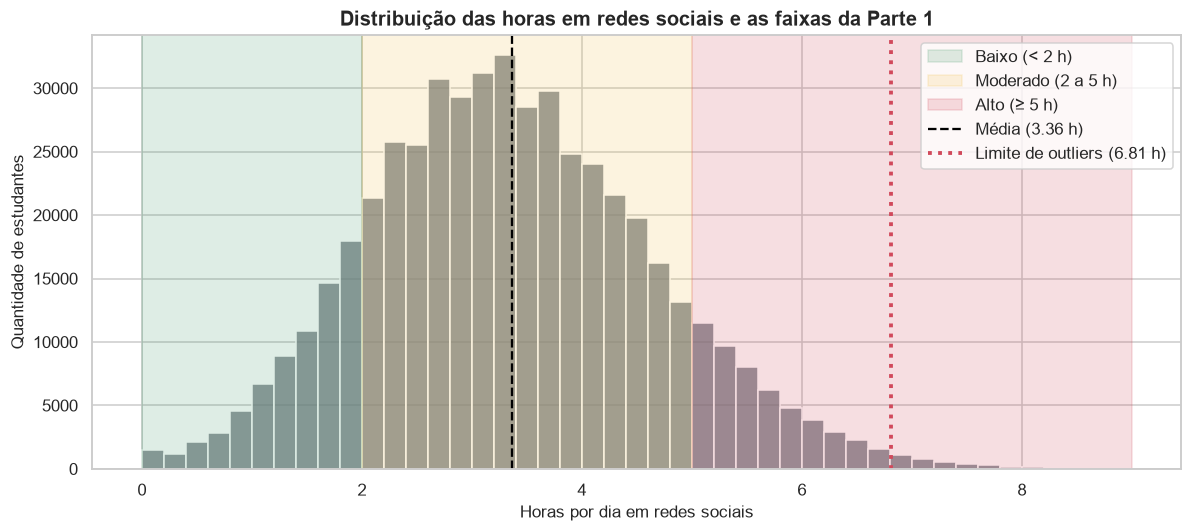

faixa_redes,estudantes,percentual
str,u32,f64
"""1-Baixo (<2h)""",71228,14.2
"""2-Moderado (2-5h)""",374313,74.9
"""3-Alto (≥5h)""",54459,10.9


In [11]:
# Faixas de uso de redes (mesmos critérios da Parte 1) sobre a distribuição
horas = inicial.select("horas_redes_sociais").collect().to_series()
media = horas.mean()

fig, ax = plt.subplots(figsize=(11, 5))
sns.histplot(horas, bins=45, color="#6C757D", edgecolor="white", ax=ax)

ax.axvspan(0, 2, color=COR_BAIXO, alpha=0.18, label="Baixo (< 2 h)")
ax.axvspan(2, 5, color=COR_MODERADO, alpha=0.18, label="Moderado (2 a 5 h)")
ax.axvspan(5, horas.max(), color=COR_ALTO, alpha=0.18, label="Alto (≥ 5 h)")
ax.axvline(media, color="black", linestyle="--", linewidth=1.5, label=f"Média ({media:.2f} h)")
ax.axvline(limite_superior, color=COR_ALTO, linestyle=":", linewidth=2.5,
           label=f"Limite de outliers ({limite_superior:.2f} h)")

ax.set_title("Distribuição das horas em redes sociais e as faixas da Parte 1")
ax.set_xlabel("Horas por dia em redes sociais")
ax.set_ylabel("Quantidade de estudantes")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

# Quantos estudantes há em cada faixa
total = horas.len()
resumo_faixas = (
    horas.to_frame()
    .select(
        pl.when(pl.col("horas_redes_sociais") < 2).then(pl.lit("1-Baixo (<2h)"))
          .when(pl.col("horas_redes_sociais") < 5).then(pl.lit("2-Moderado (2-5h)"))
          .otherwise(pl.lit("3-Alto (≥5h)")).alias("faixa_redes")
    )
    .group_by("faixa_redes")
    .agg(pl.len().alias("estudantes"))
    .with_columns((pl.col("estudantes") / total * 100).round(1).alias("percentual"))
    .sort("faixa_redes")
)
display(resumo_faixas)

> 🔎 **Interpretação.**
> - O estudante **médio (3,36 h)** está na faixa **Moderado**, que reúne a grande maioria da amostra (cerca de **74,9%**, ou 374.313 estudantes, segundo a Parte 1).
> - A faixa **Alto (≥ 5 h)** corresponde à cauda direita da distribuição: cerca de **10,9%** dos estudantes (54.459), todos acima do terceiro quartil (4,20 h).
> - Os **3.563 *outliers*** (> 6,81 h) são um subconjunto ainda menor dentro da faixa Alto, cerca de **6,5%** dela. Ou seja, o uso estatisticamente "atípico" é um caso extremo, e o grupo de risco da Parte 1 é bem mais amplo.

---
## 5. Do resumo ao padrão: bem-estar por faixa de uso e sono

A tabela de médias da Parte 1 fica mais clara como **mapa de calor**. Cada célula mostra o bem-estar médio de um grupo; quanto mais **vermelho**, menor o bem-estar.

> ▶️ Execute a célula para gerar a figura (reaproveita as categorias da Parte 1).

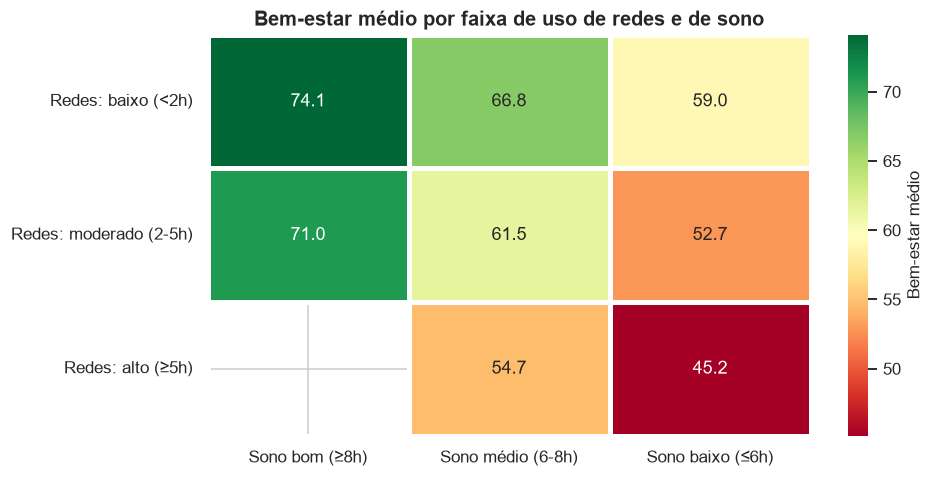

In [12]:
# Mesmas categorias da Parte 1 (sono e redes sociais)
cats = [
    pl.when(pl.col("horas_sono") <= 6).then(pl.lit("Sono baixo (≤6h)"))
      .when(pl.col("horas_sono") < 8).then(pl.lit("Sono médio (6-8h)"))
      .otherwise(pl.lit("Sono bom (≥8h)")).alias("categoria_sono"),

    pl.when(pl.col("horas_redes_sociais") < 2).then(pl.lit("Redes: baixo (<2h)"))
      .when(pl.col("horas_redes_sociais") < 5).then(pl.lit("Redes: moderado (2-5h)"))
      .otherwise(pl.lit("Redes: alto (≥5h)")).alias("categoria_redes"),
]

cruz = (
    inicial.with_columns(cats)
    .group_by(["categoria_redes", "categoria_sono"])
    .agg(pl.col("indice_bem_estar").mean().alias("media_bem_estar"))
    .collect()
    .to_pandas()
)

ordem_redes = ["Redes: baixo (<2h)", "Redes: moderado (2-5h)", "Redes: alto (≥5h)"]
ordem_sono = ["Sono bom (≥8h)", "Sono médio (6-8h)", "Sono baixo (≤6h)"]
mapa = (cruz.pivot(index="categoria_redes", columns="categoria_sono", values="media_bem_estar")
            .reindex(index=ordem_redes, columns=ordem_sono))

plt.figure(figsize=(9, 4.5))
sns.heatmap(mapa, annot=True, fmt=".1f", cmap="RdYlGn", linewidths=2, linecolor="white",
            cbar_kws={"label": "Bem-estar médio"})
plt.title("Bem-estar médio por faixa de uso de redes e de sono")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()

> 🔎 **Interpretação.**
> - O gradiente é nítido nos dois sentidos: o bem-estar cai **de cima para baixo** (mais redes) e **da esquerda para a direita** (menos sono).
> - O melhor cenário (pouco uso e sono bom) tem média de **74,1**, e o pior (alto uso e sono baixo) tem **45,2**, uma diferença de cerca de **29 pontos**.
> - A célula de **alto uso e sono bom fica em branco**: não existem estudantes nessa combinação, o que mostra que, nesta amostra, **uso intenso e pouco sono andam juntos**.

---
## 6. Correlações entre as variáveis do estudo

A correlação resume, em um número entre -1 e 1, o quanto duas variáveis variam juntas. Aqui ela é calculada **no nível do estudante** (500.000 registros), entre as variáveis centrais do tema:

- horas em redes sociais e horas de sono;
- bem-estar, capacidade de atenção e vício digital;
- risco acadêmico (indicador de desempenho).

São usados dois coeficientes: **Pearson** (relação linear) e **Spearman** (relação por ordem, menos sensível a valores extremos).

| Valor de \|r\| | Leitura |
|---|---|
| Abaixo de 0,3 | Fraca |
| De 0,3 a 0,7 | Moderada |
| Acima de 0,7 | Forte |

> ▶️ Execute a célula para gerar as duas matrizes.

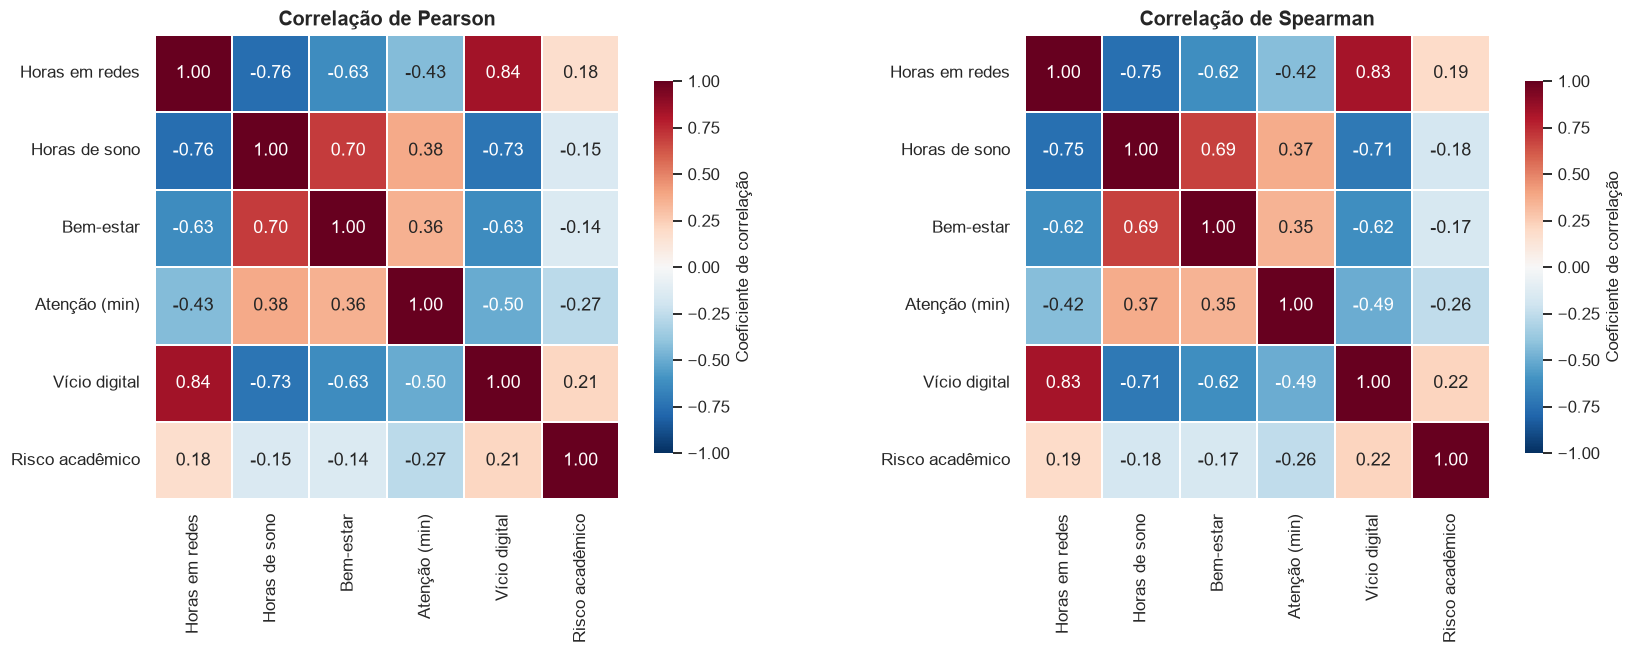

,Pearson com horas em redes
Horas de sono,-0.762
Bem-estar,-0.633
Atenção (min),-0.433
Risco acadêmico,0.178
Vício digital,0.843


In [13]:
# Matrizes de correlação no nível do estudante
colunas = {
    "horas_redes_sociais": "Horas em redes",
    "horas_sono": "Horas de sono",
    "indice_bem_estar": "Bem-estar",
    "capacidade_atencao_minutos": "Atenção (min)",
    "pontuacao_vicio_digital": "Vício digital",
    "pontuacao_risco_academico": "Risco acadêmico",
}

dados = (
    inicial.select(list(colunas.keys()))
    .drop_nulls()
    .collect()
    .to_pandas()
    .rename(columns=colunas)
)

corr_pearson = dados.corr(method="pearson")
corr_spearman = dados.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, matriz, titulo in zip(axes, [corr_pearson, corr_spearman], ["Pearson", "Spearman"]):
    sns.heatmap(matriz, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
                square=True, linewidths=1, linecolor="white",
                cbar_kws={"shrink": 0.8, "label": "Coeficiente de correlação"}, ax=ax)
    ax.set_title(f"Correlação de {titulo}")
plt.tight_layout()
plt.show()

# Correlação de cada variável com o uso de redes sociais, em ordem
display(
    corr_pearson["Horas em redes"].drop("Horas em redes")
    .sort_values().round(3).to_frame("Pearson com horas em redes")
)

> 🔎 **Como ler.** Vermelho indica correlação positiva (as variáveis crescem juntas), azul indica correlação negativa (uma cresce enquanto a outra cai) e tons claros indicam relação fraca.
>
> 🧪 **Hipótese a verificar, a partir da Parte 1:** espera-se correlação **negativa** entre horas em redes e bem-estar/sono, e **positiva** entre horas em redes e vício digital. Os valores obtidos ao executar a célula confirmam ou não essa hipótese.
>
> ⚠️ **Cuidado na leitura:** com 500 mil registros, até correlações muito pequenas são estatisticamente significativas. O que importa é o **tamanho** do coeficiente. Além disso, correlação indica associação, **não causa e efeito**.

---
## 7. Exemplo didático: correlação por país

Para ilustrar o cálculo de Pearson e de Spearman em dados agregados, os estudantes foram agrupados por **país**, com:

- **Quantidade de estudantes** (variável X);
- **Média de horas em redes sociais** (variável Y).

**Pergunta:** países com mais estudantes na amostra tendem a ter uso médio de redes sociais maior ou menor?

> ⚠️ **Ponto de atenção:** este exemplo tem valor **ilustrativo**. Como será visto, a quantidade de estudantes é praticamente a mesma em todos os países, o que limita a análise.

### 7.1 Correlação de Pearson

In [14]:
# 1. Criar o DataFrame Agregado por País
df_pais = inicial.group_by("pais").agg([
    pl.len().alias("qnt_estudantes"),          # Variável X
    pl.col("horas_redes_sociais").mean().alias("Hora_Media") # Variável Y
])

# 2. Calcular a Correlação de Pearson
correlacao = df_pais.select(
    pl.corr("qnt_estudantes", "Hora_Media", method="pearson").alias("r")
).collect()

r = correlacao["r"][0]
r2 = r**2

print(f"\n--- Análise de Correlação por País ---")
print(f"Coeficiente de Pearson (r): {r:.4f}")
print(f"Coeficiente de Determinação (r²): {r2:.4f}")

# Interpretação
if abs(r) < 0.3:
    print("Conclusão: Correlação FRACA. O tamanho do país não influencia a hora média individual.")
elif abs(r) > 0.7:
    print("Conclusão: Correlação FORTE.")
else:
    print("Conclusão: Correlação MODERADA.")


--- Análise de Correlação por País ---
Coeficiente de Pearson (r): -0.2028
Coeficiente de Determinação (r²): 0.0411
Conclusão: Correlação FRACA. O tamanho do país não influencia a hora média individual.


> 🔎 **Interpretação.**
> - **r = -0,2028:** correlação fraca e negativa.
> - **r² = 0,0411:** a quantidade de estudantes explica apenas cerca de **4,1%** da variação da hora média entre os países.
> - Com 50 países, esse coeficiente **não é estatisticamente significativo** (valor-p de aproximadamente 0,16).

### 7.2 Gráfico de dispersão

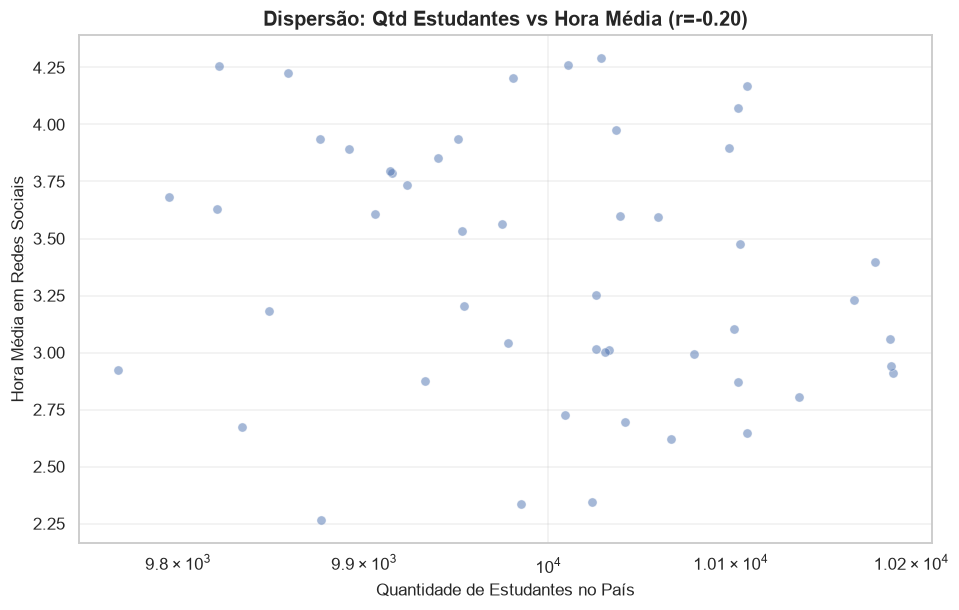

In [15]:
# Coletando os dados agregados para o gráfico
df_scatter = df_pais.collect()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_scatter.to_pandas(),
    x="qnt_estudantes",
    y="Hora_Media",
    alpha=0.5
)

plt.title(f'Dispersão: Qtd Estudantes vs Hora Média (r={r:.2f})')
plt.xlabel('Quantidade de Estudantes no País')
plt.ylabel('Hora Média em Redes Sociais')
plt.grid(True, alpha=0.3)
plt.xscale('log') # Escala logarítmica ajuda a visualizar melhor quando há cidades gigantes (capitais) e minúsculas
plt.show()

> 🔎 **Interpretação.**
> - Os pontos formam uma **nuvem sem forma definida**, sem linha ou curva de tendência.
> - O eixo X mostra que todos os países têm entre cerca de 9,8 mil e 10,2 mil estudantes. A amostra é **balanceada por país**, então a "quantidade de estudantes" varia muito pouco e quase não serve como fator explicativo.

### 7.3 Pearson × Spearman

In [16]:
# Exemplo aplicando no seu LazyFrame agregado por município
analise_correlacao = df_pais.select([
    pl.corr("qnt_estudantes", "Hora_Media", method="pearson").alias("Pearson"),
    pl.corr("qnt_estudantes", "Hora_Media", method="spearman").alias("Spearman")
]).collect()

print(analise_correlacao)

shape: (1, 2)
┌───────────┬───────────┐
│ Pearson   ┆ Spearman  │
│ ---       ┆ ---       │
│ f64       ┆ f64       │
╞═══════════╪═══════════╡
│ -0.202797 ┆ -0.228588 │
└───────────┴───────────┘


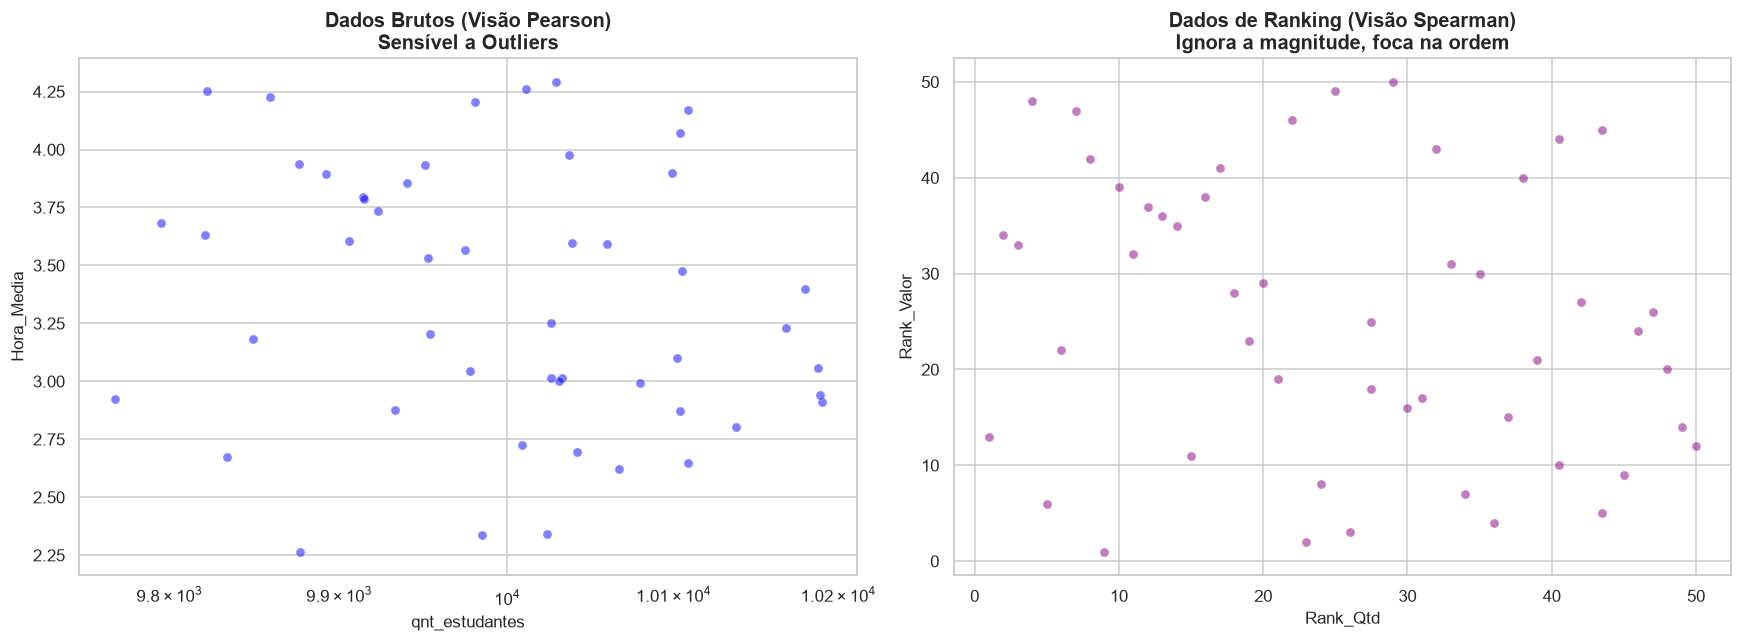

In [17]:
# 1. Preparar os dados: Criar colunas de Ranking
# O método .rank() troca o valor absoluto pela posição dele na fila (primeiro, segundo, terceiro...)
df_spearman = df_pais.with_columns([
    pl.col("qnt_estudantes").rank().alias("Rank_Qtd"),
    pl.col("Hora_Media").rank().alias("Rank_Valor")
]).collect() # Coletamos para o pandas conseguir ler

# 2. Plotar Comparativo: Dados Brutos (Pearson) vs. Ranks (Spearman)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico A: Dados Brutos (O que o Pearson enxerga)
sns.scatterplot(
    data=df_spearman.to_pandas(),
    x="qnt_estudantes",
    y="Hora_Media",
    ax=axes[0],
    alpha=0.5,
    color='blue'
)
axes[0].set_title('Dados Brutos (Visão Pearson)\nSensível a Outliers')
axes[0].set_xscale('log')

# Gráfico B: Ranks (O que o Spearman enxerga)
sns.scatterplot(
    data=df_spearman.to_pandas(),
    x="Rank_Qtd",
    y="Rank_Valor",
    ax=axes[1],
    alpha=0.5,
color='purple'
)
axes[1].set_title('Dados de Ranking (Visão Spearman)\nIgnora a magnitude, foca na ordem')

plt.tight_layout()
plt.show()

> 🔎 **Interpretação.**
> - Os dois coeficientes são **semelhantes** (Pearson de -0,203 e Spearman de -0,229) e indicam correlação **fraca e negativa**, o que mostra que o resultado não depende de valores extremos.
> - O gráfico de ranks também não mostra padrão claro.
> - Para o Spearman, com 50 países, o valor-p é de aproximadamente 0,11, portanto também não é significativo.

---
## 8. Conclusões e limitações

**Conclusões**

1. O uso de redes sociais é **moderado e simétrico**: média de 3,36 h por dia, com a maior parte dos estudantes entre 2,46 h e 4,20 h.
2. A faixa **Alto (≥ 5 h)** da Parte 1 corresponde à cauda direita da distribuição (cerca de 11% dos estudantes), e o uso estatisticamente atípico (> 6,81 h) atinge só **0,7%**.
3. O **mapa de calor** reforça o resultado da Parte 1: o bem-estar médio cai cerca de **29 pontos** do melhor para o pior cenário de uso de redes e sono.
4. A correlação por país (**r em torno de -0,2**) é fraca e não significativa, e **não responde ao tema do estudo**.

In [18]:
import os
import pandas as pd
import polars as pl

PASTA = "csv_powerbi"
os.makedirs(PASTA, exist_ok=True)

def exportar(tabela, nome):
    """Salva uma tabela em CSV pronto para o Power BI."""
    if isinstance(tabela, pl.LazyFrame):
        tabela = tabela.collect()
    if isinstance(tabela, pl.DataFrame):
        tabela = tabela.to_pandas()
    tabela.to_csv(f"{PASTA}/{nome}.csv", index=False, sep=";", decimal=",", encoding="utf-8-sig")
    print(f"{nome}.csv salvo: {len(tabela):,} linhas")

In [19]:
exportar(resumo_faixas, "05_faixas_uso_redes")
exportar(outliers, "07_outliers_horas_redes")

estat = pl.concat([metricas1, metricas2], how="horizontal").to_pandas().T.reset_index()
estat.columns = ["medida", "valor"]
estat.loc[len(estat)] = ["Limite superior outliers", limite_superior]
estat.loc[len(estat)] = ["Qtd outliers", outliers.height]
exportar(estat, "06_estatisticas_horas_redes")

05_faixas_uso_redes.csv salvo: 3 linhas
07_outliers_horas_redes.csv salvo: 3,563 linhas
06_estatisticas_horas_redes.csv salvo: 13 linhas
